# Project Introduction

The formal title of the dataset I selected for my project is “US EPA Great Lakes Water Quality Survey 2001-2019 Phytoplankton Biovolumes Summarized by Algal Group,” but it is called “GLENDA - Phytoplankton in the Great Lakes” on Brightspace, which is from where I retrieved the dataset. The spatial/geographical extent of the data is the Great Lakes, which includes Lake Erie, Lake Huron, Lake Michigan, Lake Ontario, and Lake Superior. The temporal extent of the data is 2001-2019. The dataset was last updated on 08/25/2021.

The data of interest is contained in 2 tables named “PHYTOBYGROUP” and “stations":

- The “PHYTOBYGROUP” table contains information about phytoplankton sample total biovolume itemized by algal group that was collected in the Great Lakes from 2001-2019. Each row contains unique information about a given sample collected on a certain date from a specific station.

- The “stations” table contains information about each station in the Great Lakes from which sampling took place. Each row contains data at the unique station level.

Before conducting statistical tests and creating visualizations, I loaded Python modules.

In [1]:
# Load Python modules
import pandas as pd
import numpy as np
import plotly.express as px
from IPython.display import display, Image
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import accuracy_score, confusion_matrix
from scipy.stats import binomtest, probplot

Then I loaded the 2 dataset tables and manipulated data frames for analysis.

To create my final data frame df_phytoplankton that I used for analysis, I performed the following steps:

1. I joined df_PHYTOBYGROUP and df_stations on "STATION", the station ID column.

2. I mapped each station to its corresponding Great Lake.

3. I log transformed all biovolume variables.

In [2]:
# Load dataset and manipulate data frames for analysis
df_PHYTOBYGROUP = pd.read_excel(
    io='phytoplankton_data.xlsx',
    sheet_name='PHYTOBYGROUP')
df_stations = pd.read_excel(
    io='phytoplankton_data.xlsx',
    sheet_name='stations')
df_stations = df_stations.rename(
    columns={'Station': 'STATION'})
df_phytoplankton = df_PHYTOBYGROUP.merge(
    right=df_stations,
    how='left',
    on='STATION')
def map_great_lakes(row):
    if row['STATION'][0:2] == 'ER':
        row['great_lake'] = 'Erie'
    elif row['STATION'][0:2] == 'HU':
        row['great_lake'] = 'Huron'
    elif row['STATION'][0:2] == 'MI':
        row['great_lake'] = 'Michigan'
    elif row['STATION'][0:2] == 'ON':
        row['great_lake'] = 'Ontario'
    elif row['STATION'][0:2] == 'SU':
        row['great_lake'] = 'Superior'
    else:
        row['great_lake'] = 'Huron'
    return row
df_phytoplankton = df_phytoplankton.apply(
    func=map_great_lakes,
    axis=1)
df_phytoplankton['log_BAC'] = np.log(df_phytoplankton['BAC']+1)
df_phytoplankton['log_BAP'] = np.log(df_phytoplankton['BAP']+1)
df_phytoplankton['log_CHL'] = np.log(df_phytoplankton['CHL']+1)
df_phytoplankton['log_CHR'] = np.log(df_phytoplankton['CHR']+1)
df_phytoplankton['log_CRY'] = np.log(df_phytoplankton['CRY']+1)
df_phytoplankton['log_CYA'] = np.log(df_phytoplankton['CYA']+1)
df_phytoplankton['log_EUG'] = np.log(df_phytoplankton['EUG']+1)
df_phytoplankton['log_PYR'] = np.log(df_phytoplankton['PYR']+1)
df_phytoplankton['log_UNI'] = np.log(df_phytoplankton['UNI']+1)
df_phytoplankton['log_grand_total'] = np.log(df_phytoplankton['Grand Total']+1)

Below are the first 3 rows of the final data frame:

In [3]:
# Print the first 3 rows of the final data frame
print(df_phytoplankton.head(3))

   YEAR  CRUISE STATION SAMPLE TYPE  SAMPLENUM          START_DATE  \
0  2001  Spring   ER 15         INT  01GC13I52 2001-04-15 09:36:00   
1  2001  Spring   ER 78         INT  01GC12I52 2001-04-14 09:47:00   
2  2001  Spring   ER 91         INT  01GC10I92 2001-04-13 16:20:00   

            BAC            BAP            CHL           CHR  ...    log_BAC  \
0  2.137357e+06   15094.349071  330225.536922  10602.141528  ...  14.575081   
1  6.253942e+05   26404.266273      42.860179   1077.355067  ...  13.346139   
2  2.445358e+05  915799.606523    8649.709102  51423.798255  ...  12.407121   

     log_BAP    log_CHL    log_CHR   log_CRY    log_CYA   log_EUG  log_PYR  \
0   9.622142  12.707534   9.268906  6.873030  13.489442  0.000000      0.0   
1  10.181319   3.781007   6.983192  9.284379   0.000000  0.000000      0.0   
2  13.727554   9.065397  10.847876  9.655303   8.052977  9.422037      0.0   

    log_UNI log_grand_total  
0  0.000000       14.983649  
1  3.626245       13.405621  

Below are the counts of rows and columns for the 2 source tables and the final data frame:

In [4]:
# Print the counts of rows and columns for each data frame
rows_PHYTOBYGROUP, cols_PHYTOBYGROUP = df_PHYTOBYGROUP.shape
rows_stations, cols_stations = df_stations.shape
rows_phytoplankton, cols_phytoplankton = df_phytoplankton.shape
print(f'''
df_PHYTOBYGROUP has {rows_PHYTOBYGROUP} rows 
and {cols_PHYTOBYGROUP} columns.
''')
print(f'''
df_stations has {rows_stations} rows 
and {cols_stations} columns.
''')
print(f'''
df_phytoplankton has {rows_phytoplankton} rows 
and {cols_phytoplankton} columns.
''')


df_PHYTOBYGROUP has 2780 rows 
and 16 columns.


df_stations has 130 rows 
and 5 columns.


df_phytoplankton has 2780 rows 
and 31 columns.



To answer my research questions, I am investigating temporal, spatial, and seasonal trends in phytoplankton sample biovolume in the Great Lakes to better understand the ecology of algal blooms using regression analysis, ANOVA, and classification techniques.

Below is a list of a few keywords related to my research topic:

1. Phytoplankton sample biovolume

2. Algal group

3. Temporal (year)

4. Spatial (Great Lake)

5. Seasonal (cruise)

# Research Questions and Hypotheses

## Research Question #1

My first research question is: Is there a meaningful relationship between the total phytoplankton sample biovolume across all categories and year?

Null hypothesis ($H_0$) for Correlation: $R^2=0$. In words, none of the variability in the dependent variable $y$ (total phytoplankton sample biovolume across all categories) is explained by its linear relationship with the independent variable $x$ (year).

Alternative hypothesis ($H_1$) for Correlation: $R^2>0$. In words, a statistically significant amount of the variability in $y$ is explained by its linear relationship with $x$.

Null hypothesis ($H_0$) for Simple Linear Regression: $\beta_1=0$. In words, there is no linear relationship between the independent variable $x$ (year) and the dependent variable $y$ (total phytoplankton sample biovolume across all categories).

Alternative hypothesis ($H_1$) for Simple Linear Regression: $\beta_1\neq0$. In words, there is a statistically significant linear relationship between $x$ and $y$.

## Research Question #2

My second research question is: Is the mean total phytoplankton sample biovolume across all categories equal across all five Great Lakes (Erie, Huron, Michigan, Ontario, Superior), or is at least one lake’s mean biovolume significantly different from the others?

Null hypothesis ($H_0$): $\mu_1=\mu_2=\mu_3=\mu_4=\mu_5$. In words, the population mean of the dependent variable (total phytoplankton sample biovolume across all categories) is equal for all groups or independent variables (the five Great Lakes: Erie, Huron, Michigan, Ontario, Superior).

Alternative hypothesis ($H_1$): Not all $\mu_1=\mu_2=\mu_3=\mu_4=\mu_5$. In words, the population mean of the dependent variable is different for at least one of the groups.

## Research Question #3

My third research question is: Can the cruise during which the sample was collected (Spring vs. Summer) be accurately classified using phytoplankton sample biovolume for certain algal groups?

Null hypothesis ($H_0$): $Accuracy_{model} \leq Accuracy_{NIR}$. In words, the accuracy of classification of the dependent variable (cruise) using a model based on the predictors/independent variables (phytoplankton sample biovolume for each of certain algal groups) is worse than or equal to the accuracy of the No-Information Rate (NIR) or simply guessing the majority class for each observation.

Alternative hypothesis ($H_1$): $Accuracy_{model}>Accuracy_{NIR}$. In words, the accuracy of classification of the dependent variable using a model based on the independent variables is better than the accuracy of the NIR, showing that the predictors add classification value.

# Analysis

## Research Question #1 Statistical Tests and Results

The statistical tests that I am using for my first research question are Correlation and Simple Linear Regression.

In [5]:
# RQ1 OLS Regression Test
X_1 = df_phytoplankton['YEAR']
X_1 = sm.add_constant(X_1)
y_1 = df_phytoplankton['log_grand_total']
linear_model = sm.OLS(y_1, X_1)
linear_results = linear_model.fit()
print(linear_results.summary())

                            OLS Regression Results                            
Dep. Variable:        log_grand_total   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     4.190
Date:                Sun, 18 Oct 2026   Prob (F-statistic):             0.0408
Time:                        23:17:17   Log-Likelihood:                -4649.9
No. Observations:                2780   AIC:                             9304.
Df Residuals:                    2778   BIC:                             9316.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -11.0826     11.308     -0.980      0.3

In [6]:
# RQ1 OLS Regression Results
r_sq_linear = linear_results.rsquared
F_linear = linear_results.fvalue
p_value_F_linear = linear_results.f_pvalue
y_intercept_linear, slope_linear = linear_results.params
t_slope_linear = linear_results.tvalues.loc['YEAR']
p_slope_linear = linear_results.pvalues.loc['YEAR']
print(f'''
The coefficient of determination R^2 = {r_sq_linear:.3f}.
The F-test statistic for R^2 = {F_linear:.3f}.
The p-value for R^2 = {p_value_F_linear:.3f}.
The Simple Linear Regression slope parameter beta1 = {slope_linear:.3f}.
The t-test statistic for beta1 = {t_slope_linear:.3f}.
The p-value for beta1 = {p_slope_linear:.3f}.
''')


The coefficient of determination R^2 = 0.002.
The F-test statistic for R^2 = 4.190.
The p-value for R^2 = 0.041.
The Simple Linear Regression slope parameter beta1 = 0.012.
The t-test statistic for beta1 = 2.047.
The p-value for beta1 = 0.041.



For testing Correlation, the $R^2$ value means that 0.2% of the variability in log total phytoplankton sample biovolume can be explained by its linear relationship with year, which is quite low (nearly 0) and indicates a very poor linear fit.
Using $\alpha=0.01$, our p-value $>\alpha$, so we fail to reject the null hypothesis that $R^2=0$. We do not have sufficient evidence that the alternative hypothesis is true that $R^2>0$, which indicates a statistically significant amount of the variability in $y$ is not explained by its linear relationship with $x$.

For testing Simple Linear Regression, the $\beta_1$ value means that for each 1 unit increase in year, predicted log total phytoplankton sample biovolume increases by 0.012 units, which is a relatively small amount.
Using $\alpha=0.01$, our p-value $>\alpha$ (and is equal to the p-value for the F-statistic above), so we fail to reject the null hypothesis that $\beta_1=0$. We do not have sufficient evidence that the alternative hypothesis is true that $\beta_1\neq0$, which indicates that there is not a statistically significant linear relationship between $x$ and $y$.

Note that for both of these tests, if I had chosen a higher value for $\alpha$ such as 0.05, then we would reject the null hypotheses. This indicates that there may be weak evidence to reject the null hypotheses, but caution should be taken if drawing further conclusions based on the results of this analysis.

## Research Question #1 Statistical Tests Assumptions

For Correlation and Simple Linear Regression, I tested the following assumptions:

- No outliers or overly influential points

- Normality

- Constant variance

- Mean of 0

- Independence

Note that the assumptions are the same for both tests since they are equivalent tests.

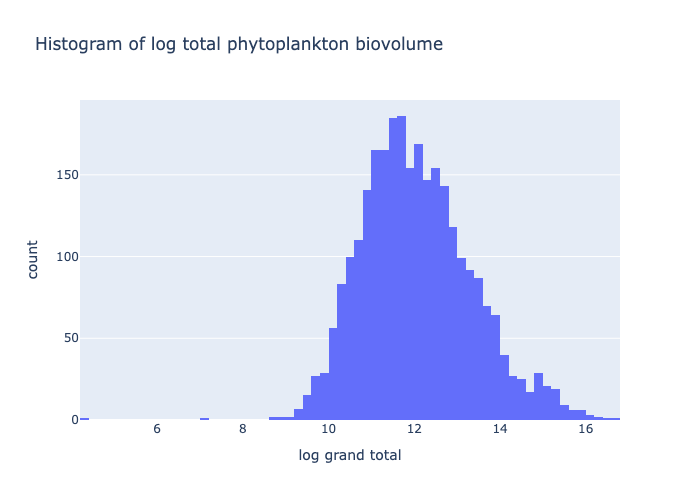

In [7]:
# RQ1 Histogram of log grand total
fig_1_hist = px.histogram(
    data_frame=df_phytoplankton,
    x='log_grand_total',
    labels={'log_grand_total': 'log grand total'},
    title='Histogram of log total phytoplankton biovolume')
fig_1_hist.write_image('plot_1_hist.png')
display(Image(filename='plot_1_hist.png'))

In constructing the above graph, I did not discover an issue in the dataset per se, such as missing or erroneous data. However, after originally creating a histogram of the 'Grand Total' variable, I realized that it is extremely right-skewed, which would make it difficult to use for analysis such as linear regression or ANOVA. Thus, I decided to take the log of 'Grand Total' to use for analysis instead of the original variable, and I named it 'log_grand_total', since taking the log of an extremely right-skewed variable tends to produce a more symmetric distribution. To be consistent with the log transformations performed to the individual biovolume variables for Research Question #3, I took $\ln(x+1)$ instead of just $\ln(x)$.

Above is a histogram of the grand total phytoplankton sample biovolume across all categories converted to the log-scale to help understand the distribution of the data. Looking at the histogram, there is a slight left skewness due to the presence of some obvious low outliers around 0 and 7, but there are no obvious high outliers due to the log-scale conversion. Since there was a very large range in observation values for total phytoplankton biovolume on the original scale, I believe it is important to keep all values in for the analysis rather than removing outliers. Also, the outliers are likely not extremely influential since they are not too extreme and there only seems to be a couple of them. Thus, the "no outliers or overly influential points" assumption is mostly met.

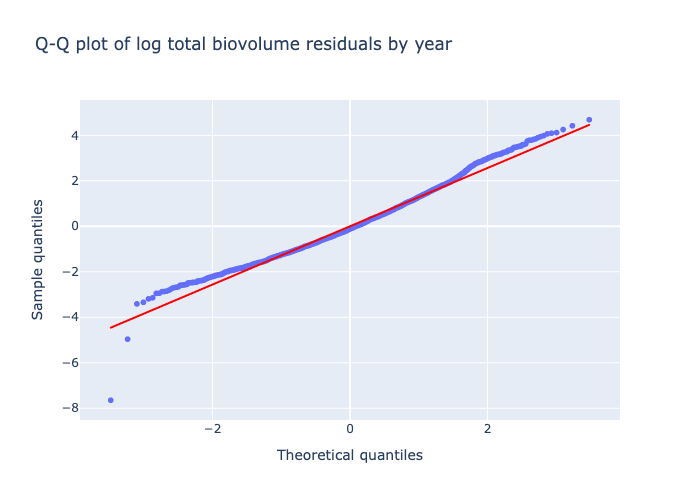

In [8]:
# RQ1 Q-Q plot of residuals
yhat_linear = y_intercept_linear+slope_linear*df_phytoplankton['YEAR']
resid_linear = df_phytoplankton['log_grand_total']-yhat_linear
resid_linear_sort = sorted(resid_linear)
qq_resid_linear = probplot(resid_linear_sort, dist='norm')
theo_quants_linear = qq_resid_linear[0][0]
sample_quants_linear = qq_resid_linear[0][1]
theo_slope_linear = qq_resid_linear[1][0]
theo_intercept_linear = qq_resid_linear[1][1]
fig_1_s_qq = px.scatter(
    x=theo_quants_linear,
    y=sample_quants_linear,
    labels={'x': 'Theoretical quantiles',                                           
            'y': 'Sample quantiles'},
    title='Q-Q plot of log total biovolume residuals by year')
fig_1_l_qq = px.line(
    x=theo_quants_linear,
    y=theo_intercept_linear+theo_slope_linear*theo_quants_linear,
    color_discrete_sequence=['red'])
fig_1_s_qq.add_traces(fig_1_l_qq.data)
fig_1_s_qq.write_image('plot_1_qq.png')
display(Image(filename='plot_1_qq.png'))

Above is a Q-Q plot of log total biovolume residuals based on using year as a linear predictor. In the middle of the plot at the medium quantiles, all of the data points of (theoretical quantile, sample quantile) fall pretty close to the theoretical quantile line of best fit.
However, most of the data points at the lower and higher quantiles lie fairly close to but above the line. The couple low outliers from the histogram are also apparent in the Q-Q plot, as they lie well below the line. There is no super obvious pattern in the data points, but there is a bit of curvature. This all indicates that there is some skewness (not perfect symmetry) in the distribution of residuals. Thus, the "normality" assumption for residuals is somewhat met.

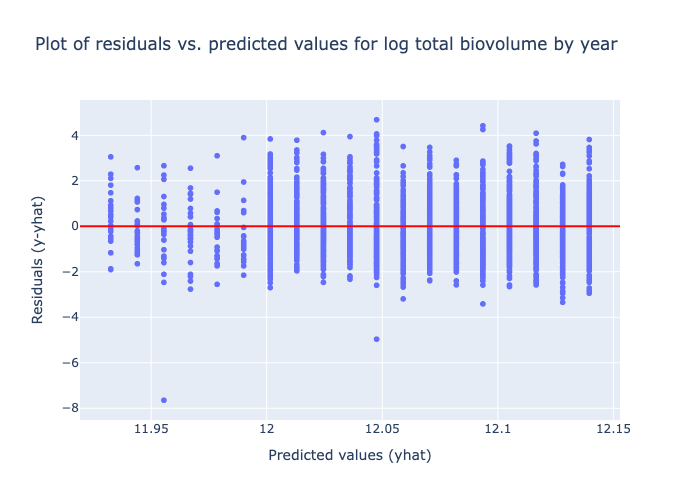

In [9]:
# RQ1 Plot of residuals vs. predicted values
fig_1_s_yhat = px.scatter(
    x=yhat_linear,
    y=resid_linear,
    labels={'x': 'Predicted values (yhat)',                                           
            'y': 'Residuals (y-yhat)'},
    title='Plot of residuals vs. predicted values' \
        ' for log total biovolume by year')
fig_1_s_yhat.add_hline(
    y=0,
    line_color='red')
fig_1_s_yhat.write_image('plot_1_yhat.png')
display(Image(filename='plot_1_yhat.png'))

Above is a scatter plot of residuals vs. predicted values for log total biovolume based on using year as a linear predictor. There is also a red horizontal line plotted at $y=0$ for analysis purposes.

There does not appear to be a fanning out or funneling in of residuals. The spread of residuals appears to be pretty constant for different $\hat{y}$ values based on the distance from largest to smallest residual for each predicted value. Thus, the "constant variance" assumption is met.

There do not appear to be subsections of residuals that are uniformly above or below 0. The residuals seem to be evenly spread above and below the $y=0$ line. Thus, the "mean of 0" assumption is met.

The residuals appear to fall in patterns of side-by-side lines rather than in a random formation because the predicted values are clearly disjoint. This is because the predictor variable 'YEAR' is discrete and only takes on values from 2001 to 2019, so there are only 19 distinct $\hat{y}$ values since they are predictions directly based on 'YEAR'. On the other hand, the response variable 'log_grand_total' is continuous and takes on many unique values. This may seem like a clear pattern, but it is simply due to the nature of the independent variable. The same stations appear across years. Thus, the residual plot alone cannot be used to determine whether independence is satisfied, so the Durbin-Watson test should be used for further analysis.

In [10]:
# RQ1 Durbin-Watson test for independence
dw_linear = durbin_watson(linear_results.resid)
print(f'The Durbin-Watson test statistic = {dw_linear:.3f}.')

The Durbin-Watson test statistic = 0.619.


The Durbin-Watson test statistic will always fall between 0 and 4. A value around 2 indicates independent residuals, while a value closer to 0 shows positive autocorrelation, and a value closer to 4 shows negative autocorrelation. The results above show that the Durbin-Watson test statistic is closer to 0, indicating positive autocorrelation in the residuals.

Thus, the "independence" assumption is not met, and interpretations of results may not be reliable. A time series model like ARIMA (Autoregressive Integrated Moving Average) would probably be more appropriate here than OLS (Ordinary Least Squares), but it is out of the scope of this class.

## Research Question #1 Final Visualization

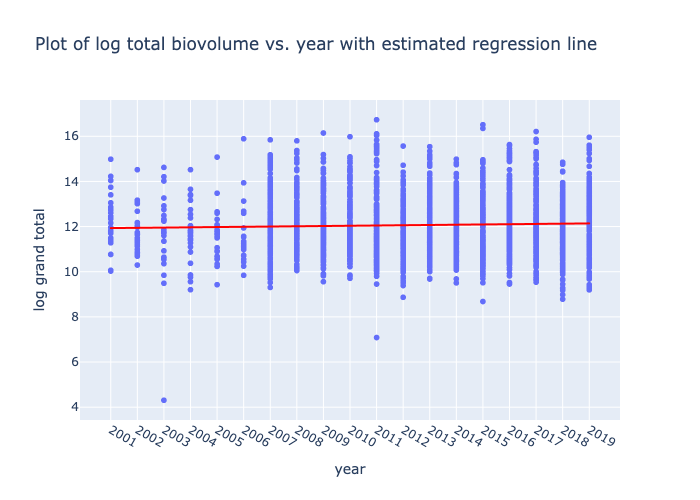

In [11]:
# RQ1 Scatter plot with estimated regression line
fig_1_s_final = px.scatter(
    data_frame=df_phytoplankton,
    x='YEAR',
    y='log_grand_total',
    labels={'YEAR': 'year',
            'log_grand_total': 'log grand total'},
    title='Plot of log total biovolume vs. year' \
        ' with estimated regression line')
fig_1_l_final = px.line(
    x=df_phytoplankton['YEAR'],
    y=y_intercept_linear+slope_linear*df_phytoplankton['YEAR'],
    color_discrete_sequence=['red'])
fig_1_s_final.add_traces(fig_1_l_final.data)
fig_1_s_final.update_layout(xaxis_type='category')
fig_1_s_final.write_image('plot_1_final.png')
display(Image(filename='plot_1_final.png'))

Above is a scatter plot (blue) of log total phytoplankton sample biovolume across all categories ($y$) vs. year ($x$) to help understand the distribution of the biovolume data separated by year. The estimated regression line of best fit (red) is also plotted on top of the scatter plot to help determine the relationship between log grand total and year and how the data has changed over time. Year can be treated as either a numeric or a factor variable for regression analysis, but I will note that I treated year as numeric in my graph for my fitted line equation. Most of the data points fall far away from the regression line, indicating a very poor linear fit. Also, the estimated regression line is nearly horizontal at $y=12$ but with a very small positive slope, which indicates a very slight increase in predicted log grand total over time, but close to no change. This confirms the lack of statistically significant results from both the Correlation and Simple Linear Regression statistical tests above.

## Research Question #2 Statistical Tests and Results

The statistical tests that I am using for my second research question are ANOVA (Analysis of Variance) and Tukey HSD (Honestly Significant Difference).

In [12]:
# RQ2 ANOVA test
anova_model = ols(
    'log_grand_total ~ C(great_lake)', 
    data=df_phytoplankton).fit() 
anova_results = anova_lm(anova_model)
print(anova_results)

                   df       sum_sq     mean_sq           F  PR(>F)
C(great_lake)     4.0  2240.233516  560.058379  651.887446     0.0
Residual       2775.0  2384.095616    0.859134         NaN     NaN


In [13]:
# RQ2 ANOVA results
F_anova = anova_results.iloc[0]['F']
p_value_F_anova = anova_results.iloc[0]['PR(>F)']
print(f'''
The F-test statistic for ANOVA = {F_anova:.3f}.
The p-value for ANOVA = {p_value_F_anova:.3f}.
''')


The F-test statistic for ANOVA = 651.887.
The p-value for ANOVA = 0.000.



For testing one-way ANOVA for $\mu$ of 5 groups, using $\alpha=0.01$, our p-value $<\alpha$, so we can reject the null hypothesis that the population mean of the dependent variable is equal for all groups. We have sufficient evidence that the alternative hypothesis is true that the population mean of log grand total is different for at least one of the Great Lakes at a statistically significant level. However, ANOVA gives us no indication as to which mean(s) is/are different from the others. Thus, we need to run a Tukey HSD test to compare means in a pairwise manner to determine differences.

Note that for the test above, the p-value is so small that it is nearly 0. This indicates that there is extremely sufficient evidence to reject the null hypothesis, so we can be confident in any further conclusions drawn based on the results of this analysis.

In [14]:
# RQ2 Tukey HSD test
tukey_results = pairwise_tukeyhsd(
    endog=df_phytoplankton['log_grand_total'],
    groups=df_phytoplankton['great_lake'],
    alpha=0.01
)
print(tukey_results)

  Multiple Comparison of Means - Tukey HSD, FWER=0.01   
 group1   group2  meandiff p-adj   lower   upper  reject
--------------------------------------------------------
    Erie    Huron  -2.2877    0.0  -2.464 -2.1114   True
    Erie Michigan  -1.7645    0.0 -1.9505 -1.5786   True
    Erie  Ontario  -0.8507    0.0 -1.0527 -0.6486   True
    Erie Superior  -2.1526    0.0 -2.3154 -1.9899   True
   Huron Michigan   0.5232    0.0  0.3339  0.7124   True
   Huron  Ontario   1.4371    0.0  1.2319  1.6422   True
   Huron Superior   0.1351 0.0631 -0.0314  0.3016  False
Michigan  Ontario   0.9139    0.0  0.7004  1.1273   True
Michigan Superior  -0.3881    0.0 -0.5648 -0.2115   True
 Ontario Superior   -1.302    0.0 -1.4955 -1.1084   True
--------------------------------------------------------


Based on the above results of the Tukey HSD test, the only pairwise comparison that is not statistically significant at the $\alpha=0.01$ level is Huron and Superior since $p-adj=0.063$.
The rest of the pairwise comparisons are statistically significant at the $\alpha=0.01$ level since $p-adj=0.0$. 
This means that the population mean of log grand total is different between all of the Great Lakes at a statistically significant level, except for Lake Huron's mean vs. Lake Superior's mean.

## Research Question #2 Statistical Test Assumptions

For ANOVA, I tested the following assumptions:

- Random and independent samples

- Normally distributed populations

- Similar population standard deviations

In [15]:
# RQ2 Counts by Great Lake
counts_lake = df_phytoplankton['great_lake'].value_counts()
total_lake = sum(counts_lake)
print(counts_lake)
print(f'''
The total observation count across all 5 lakes = {total_lake}.
The number of rows in df_phytoplankton = {rows_phytoplankton}.
''')

great_lake
Superior    789
Erie        611
Huron       564
Michigan    464
Ontario     352
Name: count, dtype: int64

The total observation count across all 5 lakes = 2780.
The number of rows in df_phytoplankton = 2780.



Since the total observation count across all 5 lakes is equal to the number of rows in df_phytoplankton, this means that each observation belongs to exactly 1 lake, and there is no double counting. Also, since I created the mapping between the 'STATION' and 'great_lake' fields, I know that each station belongs to exactly 1 lake. While I cannot confirm that samples are random and independent, based on the dataset description and the data counts, it does seem that the "random and independent samples" assumption is met.

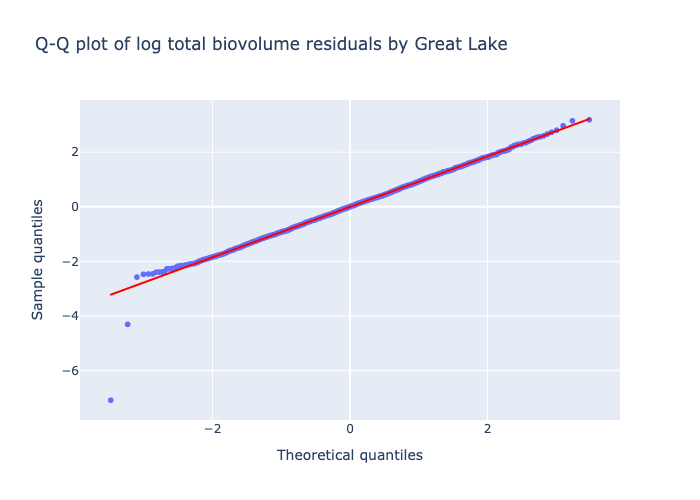

In [16]:
# RQ2 Q-Q plot of residuals
mean_anova = df_phytoplankton.groupby(
    'great_lake')['log_grand_total'].transform('mean')
resid_anova = df_phytoplankton['log_grand_total']-mean_anova
resid_anova_sort = sorted(resid_anova)
qq_resid_anova = probplot(resid_anova_sort, dist='norm')
theo_quants_anova = qq_resid_anova[0][0]
sample_quants_anova = qq_resid_anova[0][1]
theo_slope_anova = qq_resid_anova[1][0]
theo_intercept_anova = qq_resid_anova[1][1]
fig_2_s_qq = px.scatter(
    x=theo_quants_anova,
    y=sample_quants_anova,
    labels={'x': 'Theoretical quantiles',                                           
            'y': 'Sample quantiles'},
    title='Q-Q plot of log total biovolume residuals' \
        ' by Great Lake')
fig_2_l_qq = px.line(
    x=theo_quants_anova,
    y=theo_intercept_anova+theo_slope_anova*theo_quants_anova,
    color_discrete_sequence=['red'])
fig_2_s_qq.add_traces(fig_2_l_qq.data)
fig_2_s_qq.write_image('plot_2_qq.png')
display(Image(filename='plot_2_qq.png'))

Above is a Q-Q plot of log total biovolume residuals based on using Great Lake as a linear predictor. At most of the quantiles, all of the data points of (theoretical quantile, sample quantile) fall extremely close to the theoretical quantile line of best fit.
At the lowest and highest quantiles, the data points lie slightly above the line, but they are still close to the line.
Like in the histogram and the previous Q-Q plot, there are a couple low outliers that are apparent, as they lie well below the line. 
There is no super obvious pattern in the data points. There is some extremely subtle curvature, but not enough to indicate non-normality.
This all indicates that the distribution of residuals is essentially symmetric with very little skewness. Thus, the "normally distributed populations" assumption for residuals is met.

In [17]:
# RQ2 Standard deviation calculation
std_anova = df_phytoplankton.groupby(
    'great_lake')['log_grand_total'].agg('std')
range_anova = std_anova.max()-std_anova.min()
print(std_anova)
print('')
print(f'The range = {range_anova:.3f}.')

great_lake
Erie        1.080532
Huron       0.869678
Michigan    0.897759
Ontario     0.841140
Superior    0.890280
Name: log_grand_total, dtype: float64

The range = 0.239.


Above are the standard deviations of log total biovolume for each of the 5 lakes, along with the range. Based on visual inspection and personal judgment, the range in standard deviation between groups is not unreasonable given the size of the standard deviations. Thus, the "similar population standard deviations" assumption is met.

## Research Question #2 Final Visualization

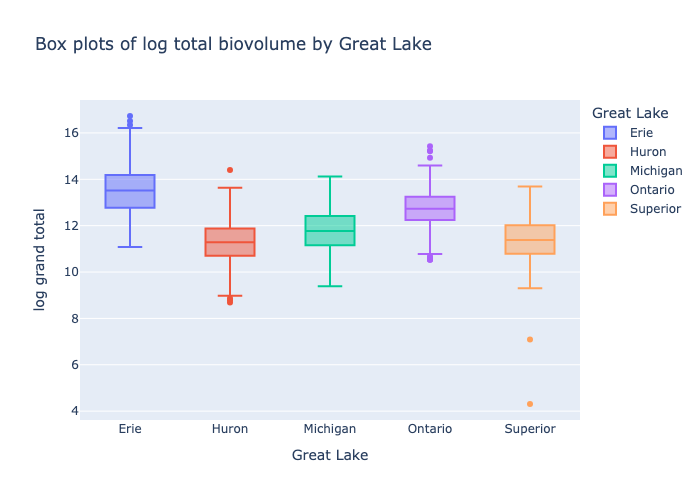

In [18]:
# RQ2 Box plot of log total phytoplankton sample biovolume by Great Lake
fig_2_final = px.box(
    data_frame=df_phytoplankton,
    x='great_lake',
    y='log_grand_total',
    color='great_lake',
    labels={'great_lake': 'Great Lake',
            'log_grand_total': 'log grand total'},
    title='Box plots of log total biovolume by Great Lake')
fig_2_final.write_image('plot_2_final.png')
display(Image(filename='plot_2_final.png'))

In constructing the above graph, I did identify an issue that needed to be fixed. I needed to create a Great Lakes variable ('great_lake') by grouping the station name variable ('STATION'). Most station names were simple to map to their corresponding Great Lake because the first 2 letters of the station name are abbreviations for the lake name (e.g., 'ER' for 'Erie', 'HU' for 'Huron', etc.). However, there were some station names that did not follow this pattern (e.g., HB1, KB479, etc.). To figure out the correct Great Lake for these stations, I searched the station latitudes and longitudes online to see in which lake they were located. However, upon doing this, I discovered that for all 11 of these differently named stations, as well as for station HU329, the latitudes and longitudes were swapped in the dataset. I will not utilize the latitudes or longitudes themselves in my analysis, but I am glad I caught the error. After looking up the locations of the differently named stations using the correct coordinates, I realized they all correspond to Lake Huron.

Above is a visual containing box plots of log total phytoplankton sample biovolume across all categories separated by Great Lake to help visualize the distributions of data and how they differ for each of the 5 Great Lakes. All five lakes have fairly symmetric distributions (little skew), as indicated by the median line being close to the middle of each box, so we can assume that each distribution's mean is nearly equal to its median. The log grand total medians for each lake are centered around 12, but they vary. Based on the box plots, the order from smallest to largest median is Huron=Superior < Michigan < Ontario < Erie. Based on the results from the ANOVA and Tukey HSD statistical tests above, we know that the population mean of log grand total is different between all lakes except for Lake Huron vs. Lake Superior at a statistically significant level.

## Research Question #3 Statistical Test and Results

The statistical test that I am using for my third research question is Classification Techniques, specifically Multiple Logistic Regression.

Note that below I used a test size of 0.3, which means that 30% of the $X$ and $y$ values are assigned to the test set, while the remaining 70% of the $X$ and $y$ values are assigned to the train set. A test size of 0.3 seems to be common in practice and seemed appropriate based on my sample size.

In [19]:
# RQ3 Multiple Logistic Regression test
X_3 = df_phytoplankton.iloc[:, [22,23,25,28]]
y_3 = df_phytoplankton['CRUISE']
X_3_train, X_3_test, y_3_train, y_3_test = train_test_split(
    X_3, y_3, 
    test_size=0.3, 
    random_state=67)
logistic_model = LogisticRegression().fit(
    X_3_train, y_3_train)
y_3_pred = logistic_model.predict(X_3_test)
logistic_model_accuracy = accuracy_score(
    y_3_test, y_3_pred)
num_correct = np.sum(y_3_pred == y_3_test)
num_trials = len(y_3_test)
classes, counts = np.unique(
    y_3_test, 
    return_counts=True)
majority_class_count = np.max(counts)
NIR = majority_class_count/num_trials
logistic_test_result = binomtest(
    k=num_correct, 
    n=num_trials, 
    p=NIR, 
    alternative='greater')
print(logistic_test_result)

BinomTestResult(k=671, n=834, alternative='greater', statistic=0.8045563549160671, pvalue=1.8000119192436375e-23)


In [20]:
# RQ3 Multiple Logistic Regression results
stat_binom = logistic_test_result.statistic
p_value_binom = logistic_test_result.pvalue
print(f'''
The No-Information Rate = {NIR:.3f}.
The Binomial test statistic = {stat_binom:.3f}
(which is the test accuracy of the classification model).
The Binomial p-value = {p_value_binom:.3f}.
''')


The No-Information Rate = 0.647.
The Binomial test statistic = 0.805
(which is the test accuracy of the classification model).
The Binomial p-value = 0.000.



For the Binomial test, since the p-value $<\alpha=0.01$, we can reject the null hypothesis that the accuracy of the model $\leq$ that of the NIR or simply guessing the majority class for each observation. We have sufficient evidence that the alternative hypothesis is true that the accuracy of classification of the dependent variable using a model based on the independent variables $>$ the accuracy of the NIR, showing that the predictors add classification value at a statistically significant level.

Note that for the test above, the p-value is so small that it is nearly 0. This indicates that there is extremely sufficient evidence to reject the null hypothesis, so we can be confident in any further conclusions drawn based on the results of this analysis.

## Research Question #3 Statistical Test Assumptions

For Multiple Logistic Regression, I tested the following assumptions:

- Binary outcome

- Independent observations

- Sufficient sample size per variable

- No severe multicollinearity

- Absence of extreme outliers

- Linearity in the logit

In [21]:
# RQ3 Number of cruise outcomes
cruise_unique = df_phytoplankton['CRUISE'].unique()
print(cruise_unique)

<StringArray>
['Spring', 'Summer']
Length: 2, dtype: str


As the above output shows, there are only 2 possible values of the 'CRUISE' variable: 'Spring' and 'Summer'. Thus, the "binary outcome" assumption is satisfied.

In [22]:
# RQ3 Counts by cruise
counts_cruise = df_phytoplankton['CRUISE'].value_counts()
total_cruise = sum(counts_cruise)
print(counts_cruise)
print(f'''
The total observation count across both cruises = {total_cruise}.
The number of rows in df_phytoplankton = {rows_phytoplankton}.''')

CRUISE
Summer    1702
Spring    1078
Name: count, dtype: int64

The total observation count across both cruises = 2780.
The number of rows in df_phytoplankton = 2780.


Since the total observation count across both cruises is equal to the number of rows in df_phytoplankton, this means that each observation belongs to exactly 1 cruise, and there is no double counting. While I cannot confirm that samples are independent, based on the dataset description and the data counts, it does seem that the "independent observations" assumption is met.

In [23]:
# RQ3 Sample size of biovolume variables
zeros_log_bio = (df_phytoplankton==0).sum()[21:30]
zeros_log_bio = zeros_log_bio.sort_values()
print(zeros_log_bio)

log_BAC       0
log_CHR       2
log_CRY       3
log_BAP      34
log_CYA      36
log_CHL     391
log_PYR     727
log_UNI    2534
log_EUG    2694
dtype: int64


Based on the above counts of values of 0 per biovolume variable, log_UNI and log_EUG have extremely high counts of zeros (nearly all their observations are 0). This means that neither variable will have much prediction power when used in a logistic regression model since they cannot provide much useful information. Thus, log_UNI and log_EUG should not be used with this classification technique, so I dropped them from this analysis. After removing the 2 poorly populated groups, the "sufficient sample size per variable" assumption is met.

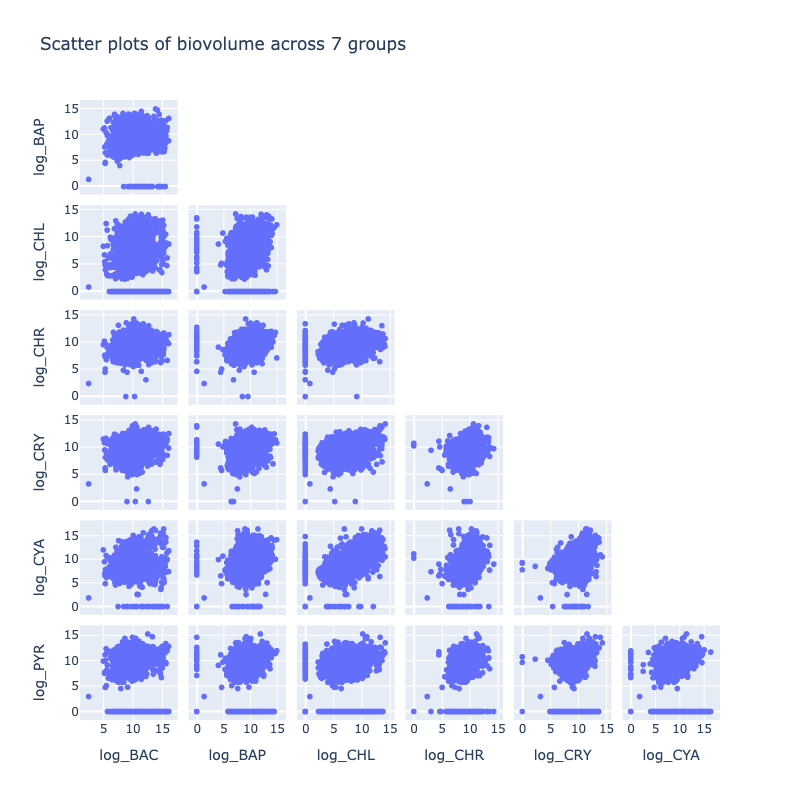

In [24]:
# RQ3 Scatter plot matrix of biovolume variables
fig_3_scatter = px.scatter_matrix(
    data_frame=df_phytoplankton, 
    dimensions=['log_BAC', 'log_BAP', 'log_CHL', 'log_CHR', 
                'log_CRY', 'log_CYA', 'log_PYR'],
    title='Scatter plots of biovolume across 7 groups')
fig_3_scatter.update_traces(showupperhalf=False, diagonal_visible=False)
fig_3_scatter.write_image('plot_3_scatter.png', width=800, height=800)
display(Image(filename='plot_3_scatter.png'))

In constructing the above visualization, I did not discover an issue in the dataset per se, such as missing or erroneous data. However, after originally creating a scatter plot matrix of the 7 remaining biovolume variables, I realized that the variables appeared to be very right-skewed, which would make them difficult to use for analysis. Thus, I decided to take the log of each of the 7 remaining biovolume variables to use for analysis instead of the original variable, and I created 7 new variables named by adding 'log_' to the beginning (e.g., 'BAC' became 'log_BAC', 'BAP' became 'log_BAP', etc.), since taking the log of an extremely right-skewed variable tends to produce a more symmetric distribution.

While the grand total variable did not have any values of 0 on the original scale, the individual variables did. Taking $\ln(0)$ is not allowed since it results in $-\infty$, which created issues when trying to perform logistic regression. Thus, I decided to take $\ln(x+1)$ instead of just $\ln(x)$  for each biovolume variable to preserve values of 0 and eliminate the errors. Note that this technique potentially introduced some bias. Taking the log transform resulted in eliminating extremely high outliers, as well as potentially helping to satisfy linearity in the logit (discussed later) for some of the predictors since converting to the log-scale is common in logistic regression.

Above is a scatter plot matrix of log phytoplankton sample biovolume for each of the 7 well-populated algal groups to help visualize the pairwise relationships between each of the 7 variables. Most scatter plots contain dense clumps of data points, so it is hard to discern any obvious pairwise relationships between variables. However, there are possibly weak positive relationships between most or all of the variables, which means that an increase in $x$ is associated with a very slight increase in $y$. For the purpose of my analysis, which is classification accuracy, none of the multicollinearity is likely to be severe enough to negatively impact my analysis, but I used VIF (Variance Inflation Factor) below to check this.

In [25]:
# RQ3 VIF to test multicollinearity
X_3_VIF = df_phytoplankton.iloc[:, [21,22,23,24,25,26,28]]
X_3_VIF = sm.add_constant(X_3_VIF)
df_VIF = pd.DataFrame({
    'Predictor': X_3_VIF.columns,
    'VIF': [variance_inflation_factor(X_3_VIF.values, i)
            for i in range(len(X_3_VIF.columns))]
})
print(df_VIF[1:])

  Predictor       VIF
1   log_BAC  1.168429
2   log_BAP  1.184510
3   log_CHL  1.390614
4   log_CHR  1.447562
5   log_CRY  1.192454
6   log_CYA  1.470058
7   log_PYR  1.096573


A VIF score of 1 means no correlation, a VIF value between 1 and 5 indicates moderate correlation which is generally acceptable, and VIF > 5 means high multicollinearity and unstable coefficients which requires dropping or combining predictors.
All biovolume predictors have VIF scores between 1 and 2. This means there is hardly any correlation between any of the variables.
Thus, the "no severe multicollinearity" assumption is confirmed met, and no further action needs to be taken.

In [26]:
# RQ3 Descriptive statistics tables by cruise
df_phyto_spring = df_phytoplankton[df_phytoplankton['CRUISE']=='Spring']
df_phyto_spring = df_phyto_spring.iloc[:, [21,22,23,24,25,26,28]]
print('Spring summary:')
print(df_phyto_spring.describe())
df_phyto_summer = df_phytoplankton[df_phytoplankton['CRUISE']=='Summer']
df_phyto_summer = df_phyto_summer.iloc[:, [21,22,23,24,25,26,28]]
print('\nSummer summary:')
print(df_phyto_summer.describe())

Spring summary:
           log_BAC      log_BAP      log_CHL      log_CHR      log_CRY  \
count  1078.000000  1078.000000  1078.000000  1078.000000  1078.000000   
mean     10.210579     8.582524     4.470946     8.714922     9.586172   
std       2.229561     1.973542     3.285237     1.213476     1.148948   
min       2.446590     0.000000     0.000000     0.000000     0.000000   
25%       8.587345     7.654170     0.000000     8.068577     8.950159   
50%       9.668950     8.598371     5.364026     8.658049     9.608236   
75%      11.533641     9.635425     6.953699     9.376156    10.322012   
max      16.066296    14.773549    13.668512    13.440602    12.917365   

           log_CYA      log_PYR  
count  1078.000000  1078.000000  
mean      7.526537     5.964988  
std       1.857781     4.652559  
min       0.000000     0.000000  
25%       7.010639     0.000000  
50%       7.676257     7.654889  
75%       8.359189     9.760951  
max      13.677612    14.393651  

Summer sum

Above are 2 descriptive statistics tables of log phytoplankton sample total biovolume for each of the 7 well-populated algal groups separated by cruise (Spring vs. Summer) to help understand the distributions of data. Across both cruises, the minimum ranges from 0 to around 5, and the maximum ranges from around 13 to around 16. None of the summary statistics stand out as alarming in a way that would indicate any highly influential data points. Thus, the "absence of extreme outliers" assumption is met.

Note that the 7 remaining log biovolume variables have summer counts that are around 600 higher than spring counts. This indicates that if we had no predictors or data with which we could develop or train the classification model, the default prediction of cruise would be summer since it is the majority class. This is the definition of the NIR that is mentioned above.

In [27]:
# RQ3 Box-Tidwell test for linearity in the logit
X_3_logit = df_phytoplankton.iloc[:, [21,22,23,24,25,26,28]]
y_3_logit = df_phytoplankton['CRUISE']
y_3_logit = y_3_logit.map(
    {'Spring': 0,
     'Summer': 1})
for col in X_3_logit.columns:
    X_3_logit[f'{col}_ln'] = X_3_logit[col] * np.log(X_3_logit[col]+1)
X_3_logit = sm.add_constant(X_3_logit)
logit_model = sm.Logit(y_3_logit, X_3_logit).fit()
print(logit_model.pvalues[8:])

Optimization terminated successfully.
         Current function value: 0.266687
         Iterations 8
log_BAC_ln    5.133079e-22
log_BAP_ln    6.158721e-01
log_CHL_ln    1.034350e-02
log_CHR_ln    9.911486e-05
log_CRY_ln    1.794835e-01
log_CYA_ln    7.737117e-06
log_PYR_ln    2.908595e-02
dtype: float64


Linearity of the logit means the predictors must have a linear relationship with the log-odds (logit) of the outcome variable. In my analysis, I was focused on classification accuracy, not logistic model fitting, so I did not produce estimated regression coefficients for the independent variables. Thus, I determined the best way to check linearity of the logit was to use the Box-Tidwell test, which involves adding an interaction term for each predictor to the model, where the interaction is between the predictor itself and the natural log of the predictor. After fitting a logit model to the data, if an interaction term is deemed statistically significant, then the linearity assumption is violated for that independent variable.

Based on the above results, at an $\alpha=0.01$ level, the interaction terms for log_BAC, log_CHR, and log_CYA are statistically significant, while log_BAP, log_CHL, log_CRY, and log_PYR are not. I already performed a log transformation on all the biovolume variables, which is supposed to help fix violations of linearity in the logit, so I did not think it was appropriate to further transform the variables. Thus, I decided to drop log_BAC, log_CHR, and log_CYA from this analysis, especially because results were still very statistically significant (just slightly less so). After dropping the 3 predictors that violated linearity, the "linearity in the logit" assumption is met.

## Research Question #3 Final Visualization

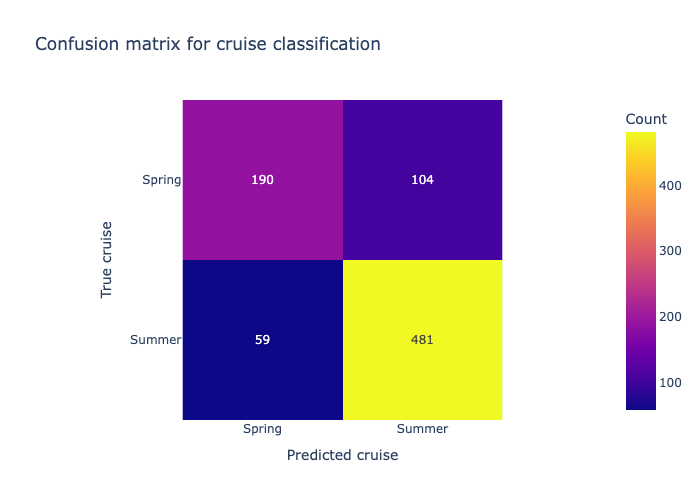

In [28]:
# RQ3 Confusion matrix for cruise classification
y_3_cm = confusion_matrix(y_3_test, y_3_pred, labels=classes)
fig_3_final = px.imshow(
    img=y_3_cm, x=classes, y=classes, text_auto=True,
    labels={'x': 'Predicted cruise',
            'y': 'True cruise',
            'color':'Count'},
    title='Confusion matrix for cruise classification')
fig_3_final.write_image('plot_3_final.png')
display(Image(filename='plot_3_final.png'))

Above is a confusion matrix for the cruise classification. It shows how the values of cruise predicted by the Multiple Logistic Regression model ("Predicted cruise") compare to the true values of cruise in the test set ("True cruise"). We can see that there are higher numbers in the top left and bottom right squares of the confusion matrix than the top right and bottom left. This indicates that our classification model is not perfect, but it is successful overall at predicting the correct value of cruise based on the values of the four valid log biovolume predictors, since the predicted cruise and true cruise values match in the top left and bottom right squares. Since the numbers in the top right and bottom left squares of the confusion matrix are much smaller, the error rate of the classification model is fairly low. The results of the Binomial statistical test confirm that the Multiple Logistic Regression model is better at classifying test observations than if the model had no information and instead guessed the most popular cruise for every test observation, which would be Summer. However, since the accuracy of the classification model is around 80%, there is still room for improvement.

# Conclusions

To summarize, below are the answers to my 3 research questions:

1. RQ1: No, there is not a meaningful relationship between the total phytoplankton sample biovolume across all categories and year.

2. RQ2: Yes, at least one lake’s mean biovolume is significantly different from the others. Each lake’s is different except for Lake Huron vs. Lake Superior.

3. RQ3: Yes, the cruise during which the sample was collected can be accurately classified using phytoplankton sample biovolume for certain algal groups.

For further analysis, I would like to investigate solutions to violated assumptions:

- For RQ1, the "independence" assumption was violated. I used OLS to model the relationship between log total biovolume and year, but I would like to investigate instead using a time series model like ARIMA to better fit the data since year is a time variable and ARIMA can handle autocorrelation. That way, I would not have to perform the regression analysis even after learning that the assumption was violated and knowing that the results of the analysis were unreliable.

- For RQ3, the "linearity in the logit" assumption was violated. I used a log-scale conversion on all biovolume variables, but I would like to investigate instead adding higher-order polynomial terms or using a regression spline to better fit the biovolume variables that were not linear in the logit even after being log transformed. That way, I would not have to drop the predictors that violated the assumption and could instead utilize them in my classification model to potentially add further predictive power.

Because I want to be careful not to jump to conclusions on items I did not test, if I consider my results holistically, I do not think they demonstrate much about phytoplankton aside from the answers to the specific research questions I analyzed. However, moving forward, I think this information could help guide the next research questions to investigate. For example, the results from my second and third research questions could be used to write a new research question that tests Great Lake and cruise together and considers their combined relationship with phytoplankton sample biovolume. In the future, I believe my research could be applied to other lakes or bodies of water to gain insights into the behavior of their ecology and algal blooms.

# Appendix

Please see the following separate files for more information:

- "Final_Project_Code.py" is a Python script that contains all the code used to produce the results in this report.

- "phytoplankton_data.xlsx" is a supporting data file that contains the original dataset used in the analysis in this report.